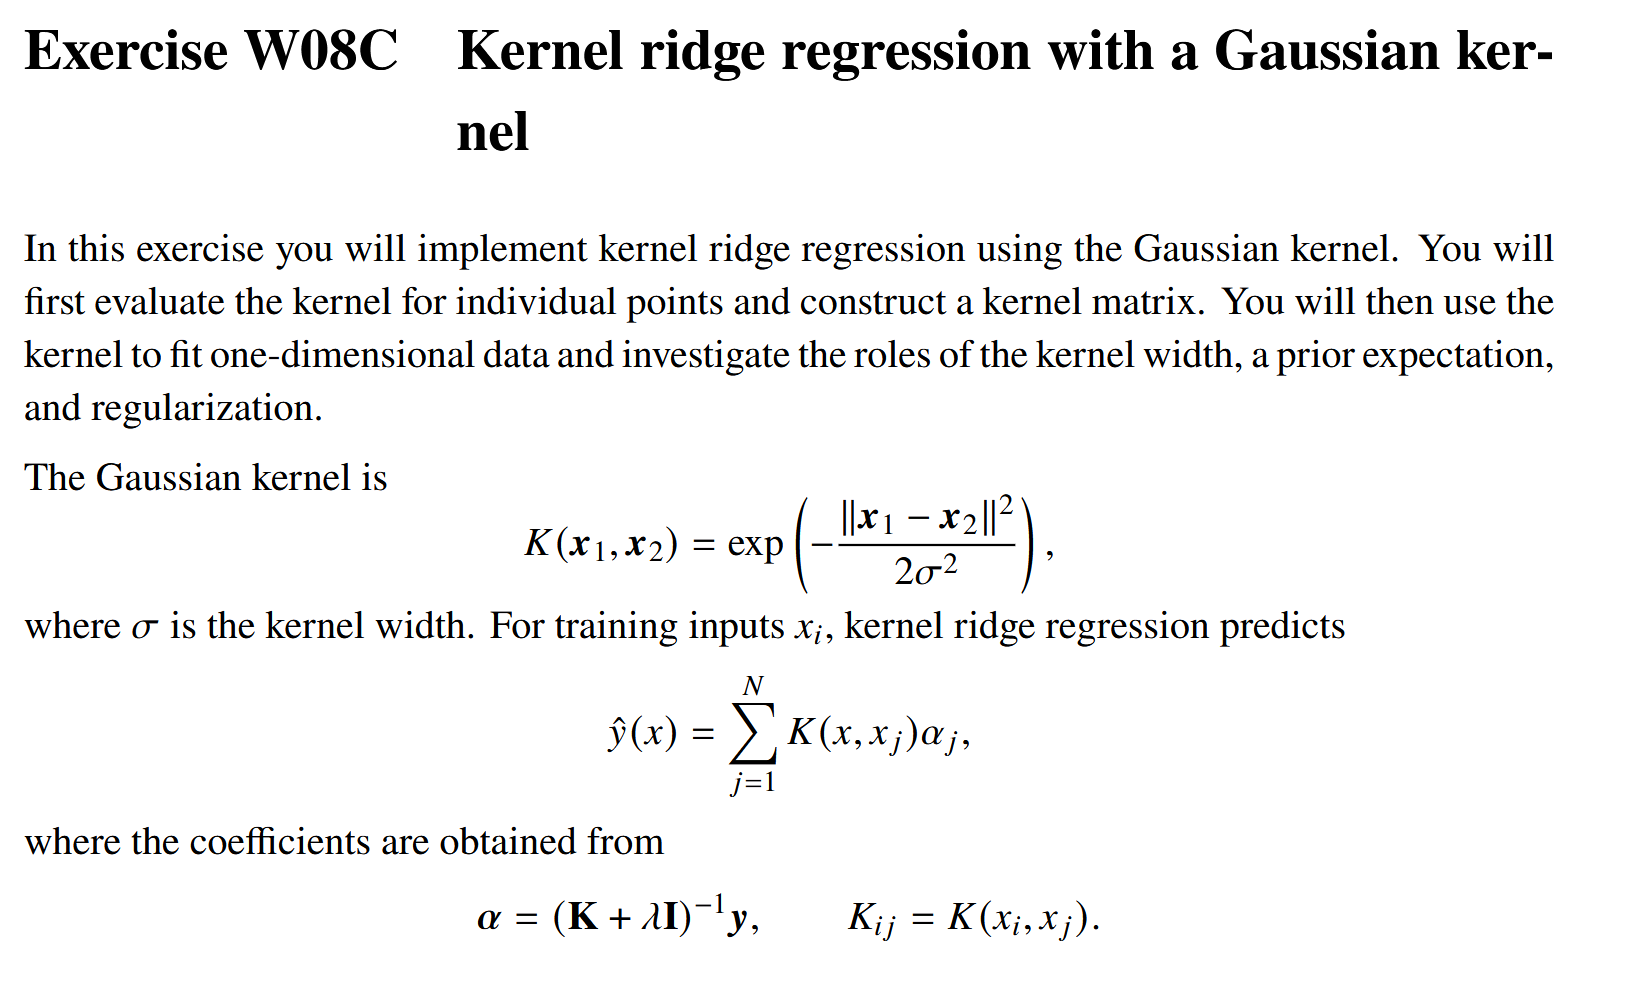
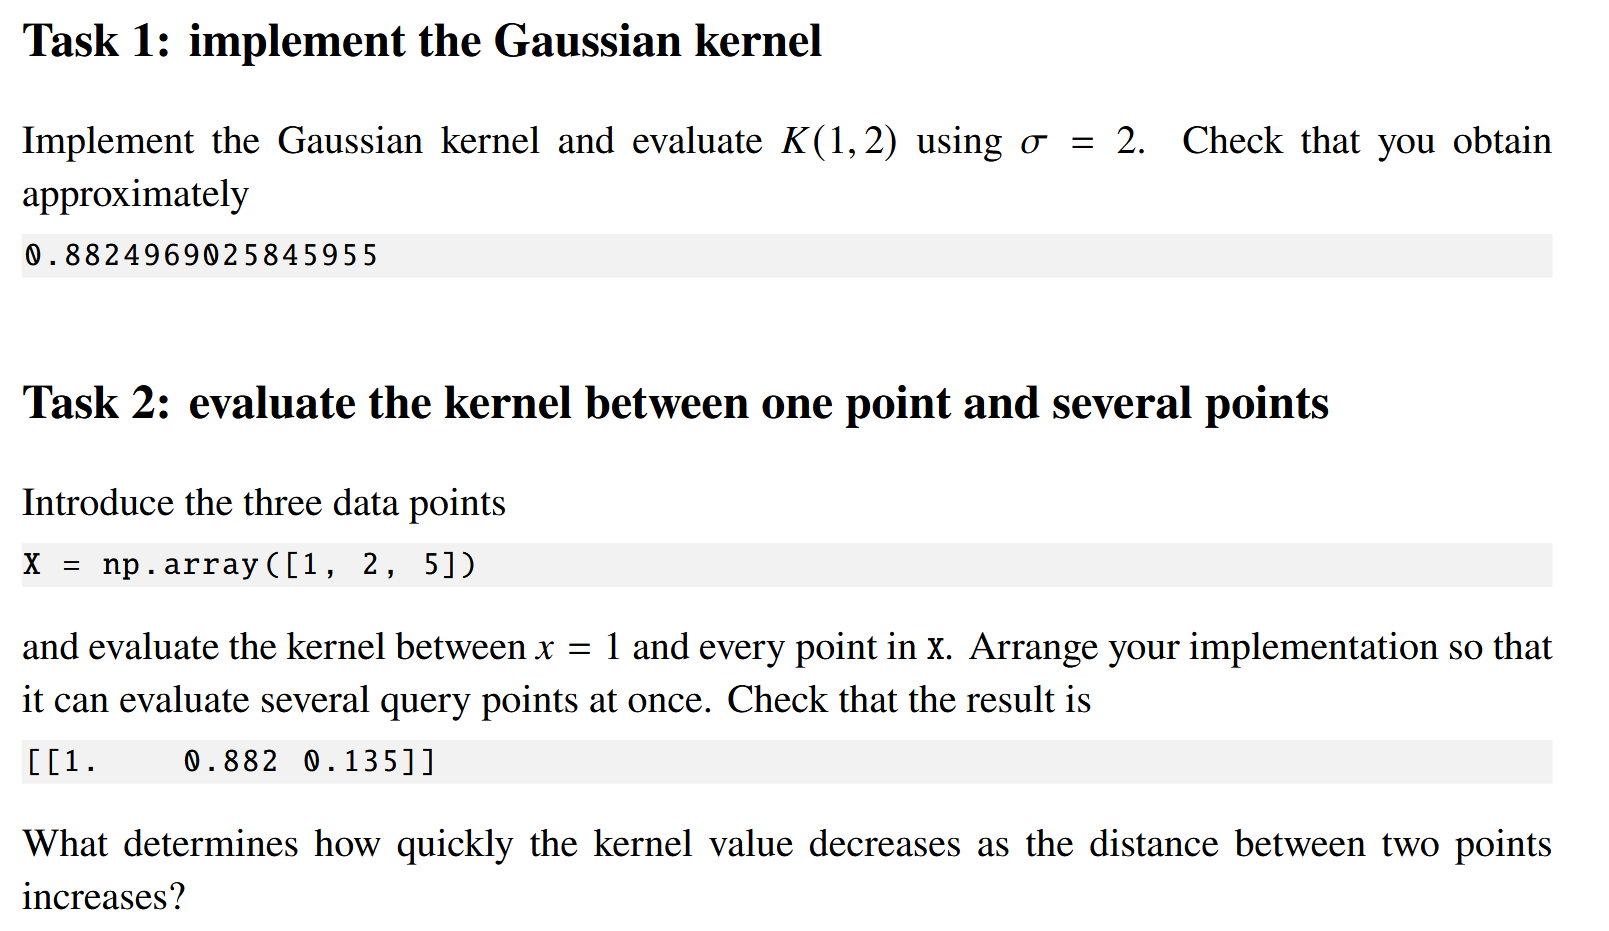

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

class KernalRidgeRegression:
    def __init__(self, sigma, lam):
        self.sigma = sigma
        self.l = lam
        self.alpha = None

    def K(self, x1, x2):
        return np.exp(-(x1-x2)**2/(2*self.sigma**2))

    def fit(self, X, y):
        self.X_train = X
        self.N = len(X)

        self.K_fit = np.array([[self.K(X[i], X[j]) for j in range(self.N)] 
                                                   for i in range(self.N)])

        self.alpha = np.linalg.inv(self.K_fit + self.l * np.identity(self.N)) @ y
        return self.alpha

    def predict(self, X):
        if type(self.alpha) == type(None):
            raise ValueError('No α, run .fit() first')

        M = len(X)

        K_pred = np.array([[self.K(X[i], self.X_train[j]) for j in range(self.N)]
                                                          for i in range(M)])
        
        return K_pred @ self.alpha

krr = KernalRidgeRegression(2, 0)
print(f'K(1,2) = {krr.K(1,2)}')

points = np.array([1, 2, 5])
print(krr.K(points, 1))

K(1,2) = 0.8824969025845955
[1.         0.8824969  0.13533528]


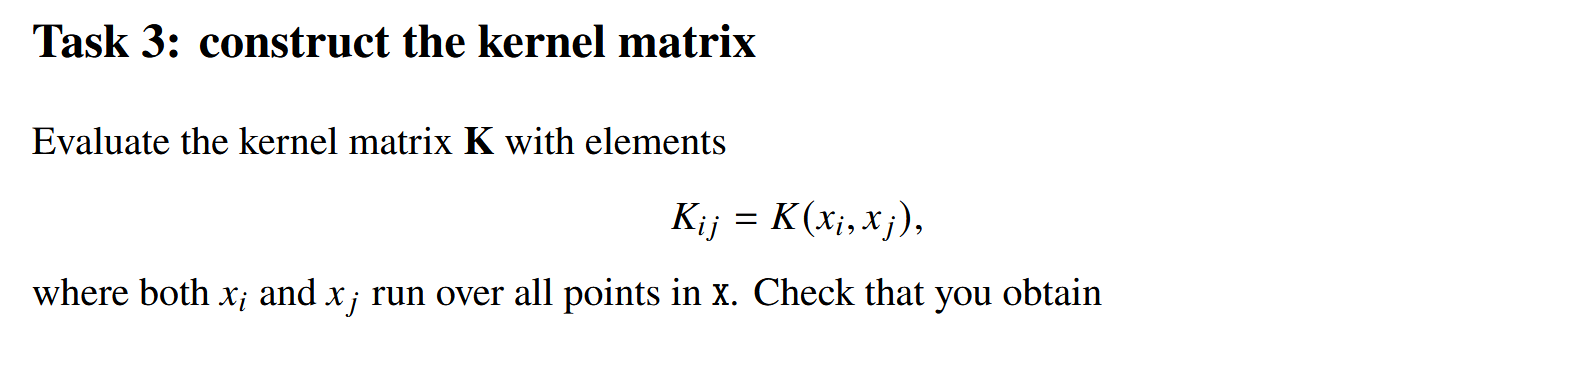
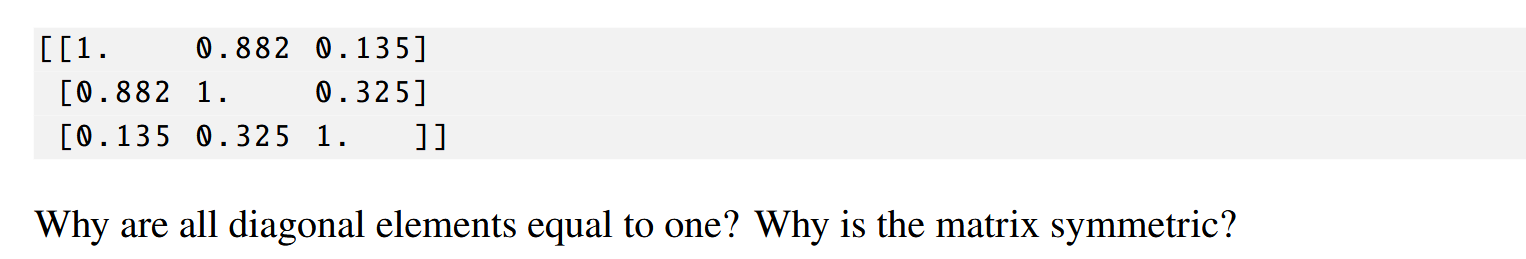

In [46]:
print(np.array([krr.K(points, x) for x in points]))

[[1.         0.8824969  0.13533528]
 [0.8824969  1.         0.32465247]
 [0.13533528 0.32465247 1.        ]]


They are 1 because x1=x2 so we have $K(x_1,x_2)=\exp(-0)=1$

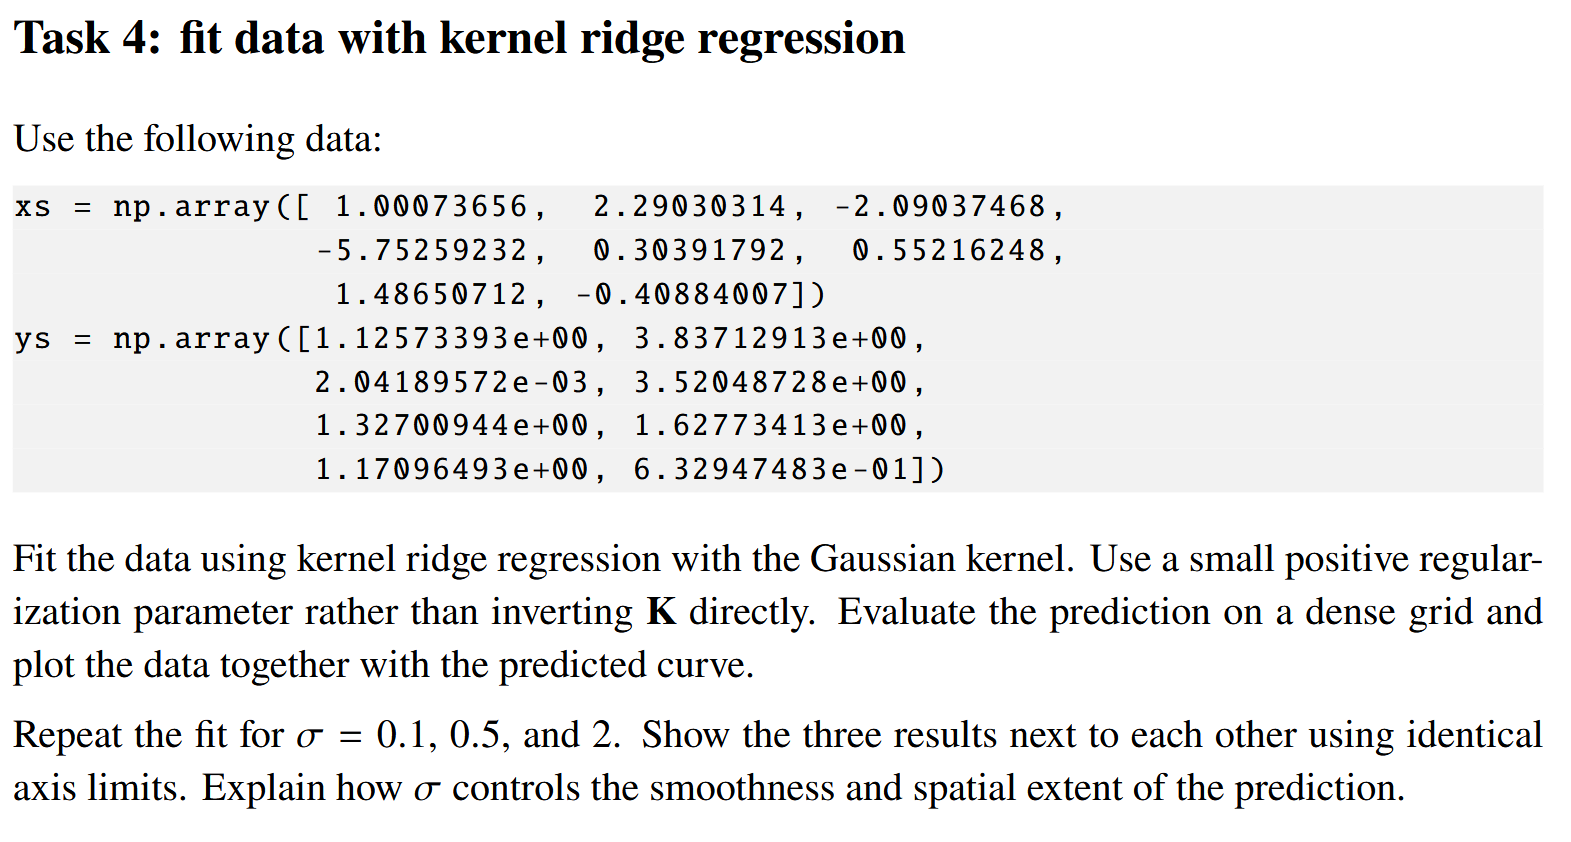

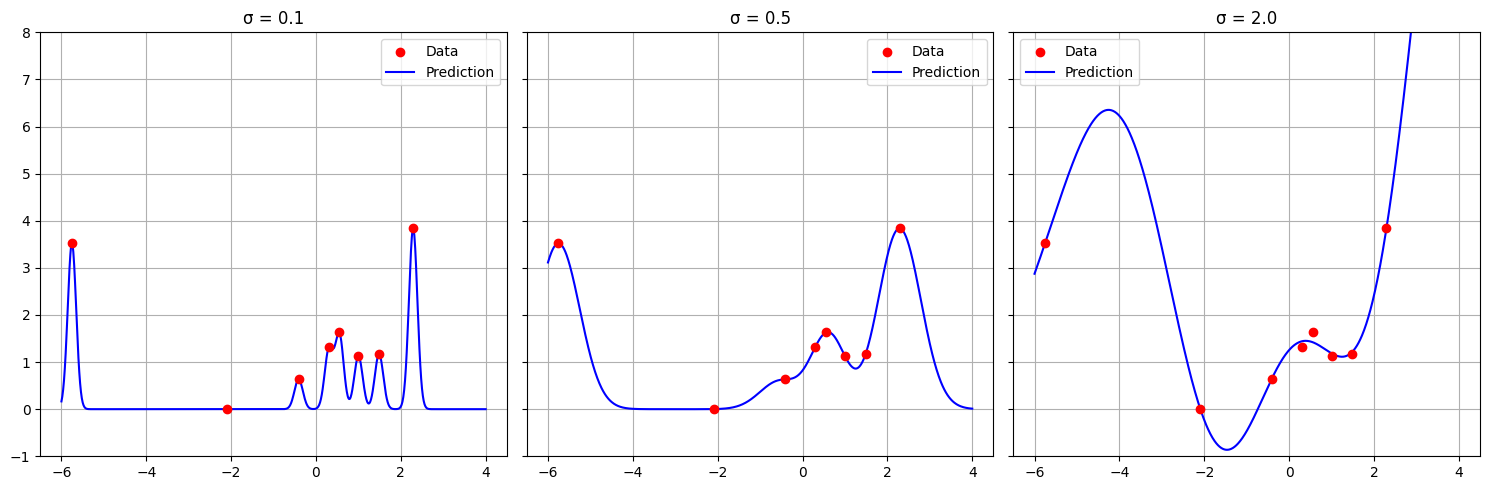

In [47]:
xs = np.array ([1.00073656, 2.29030314, -2.09037468, -5.75259232, 0.30391792, 0.55216248, 1.48650712, -0.40884007])
ys = np.array ([1.12573393, 3.83712913, 2.04189572e-3, 3.52048728, 1.32700944, 1.62773413, 1.17096493, 6.32947483e-1])

sigmas = [0.1, 0.5, 2.0]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

x_lin = np.linspace(-6, 4, 1000)

λ = 1e-4

for ax, sig in zip(axes, sigmas):
    krr = KernalRidgeRegression(sig, λ)
    krr.fit(xs, ys)

    y_lin = krr.predict(x_lin)

    ax.scatter(xs, ys, color='red', zorder=5, label='Data')
    ax.plot(x_lin, y_lin, color='blue', label='Prediction')

    ax.set_ylim(-1, 8)
    ax.set_title(f'σ = {sig}')
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()

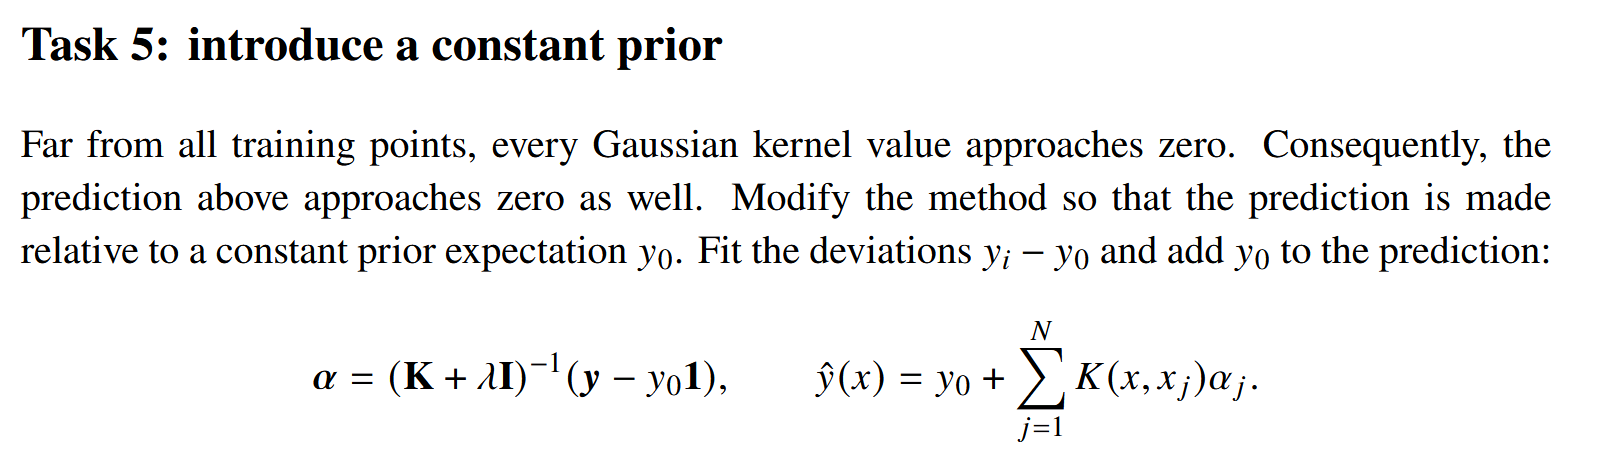
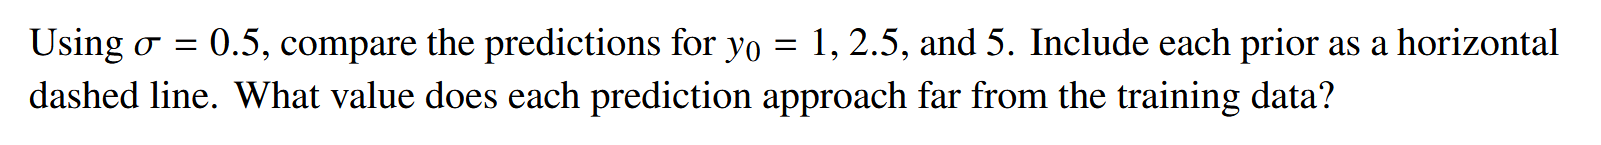

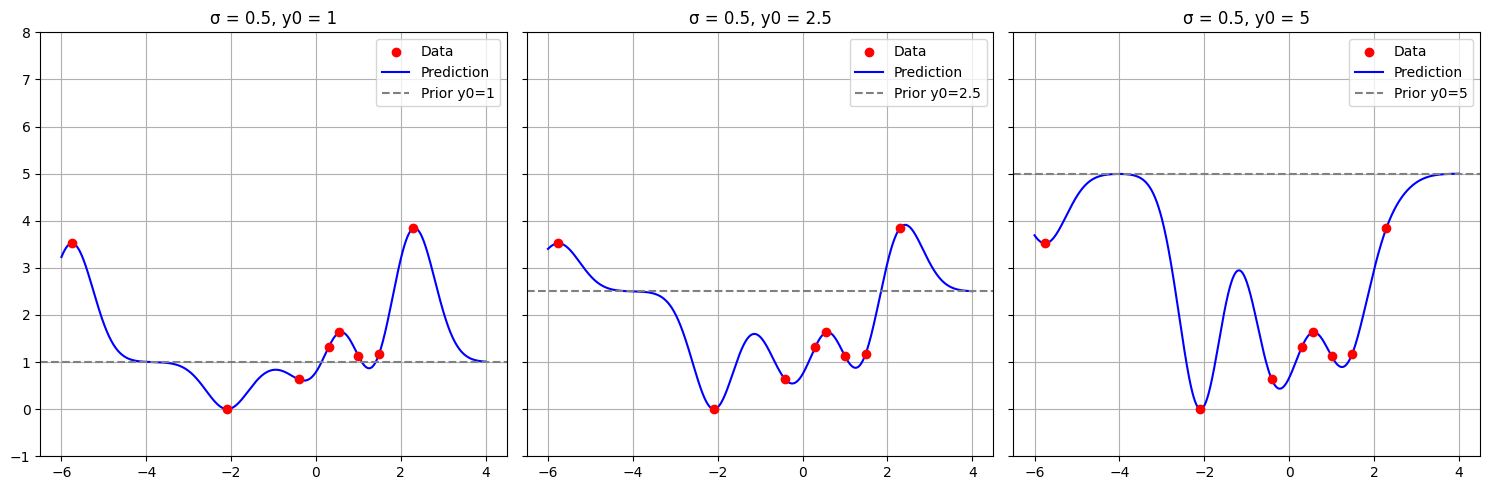

In [48]:
class PriorKernalRidgeRegression(KernalRidgeRegression):
    def __init__(self, *args, y0=0.0, **kwargs):
        super().__init__(*args, **kwargs)
        self.y0 = y0

    def fit(self, X, y):
        super().fit(X, y)
        
        self.alpha = (np.linalg.inv(self.K_fit + self.l * np.identity(self.N)) 
                      @ (y - self.y0))
        
        return self.alpha
    
    def predict(self, X):
        return super().predict(X) + self.y0

y0s = [1, 2.5, 5]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, y0 in zip(axes, y0s):
    krr = PriorKernalRidgeRegression(0.5, λ, y0=y0)
    krr.fit(xs, ys)

    y_lin = krr.predict(x_lin)

    ax.scatter(xs, ys, color='red', zorder=5, label='Data')
    ax.plot(x_lin, y_lin, color='blue', label='Prediction')

    ax.axhline(y0, color='gray', linestyle='--', label=f'Prior y0={y0}')

    ax.set_ylim(-1, 8)
    ax.set_title(f'σ = {0.5}, y0 = {y0}')
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()

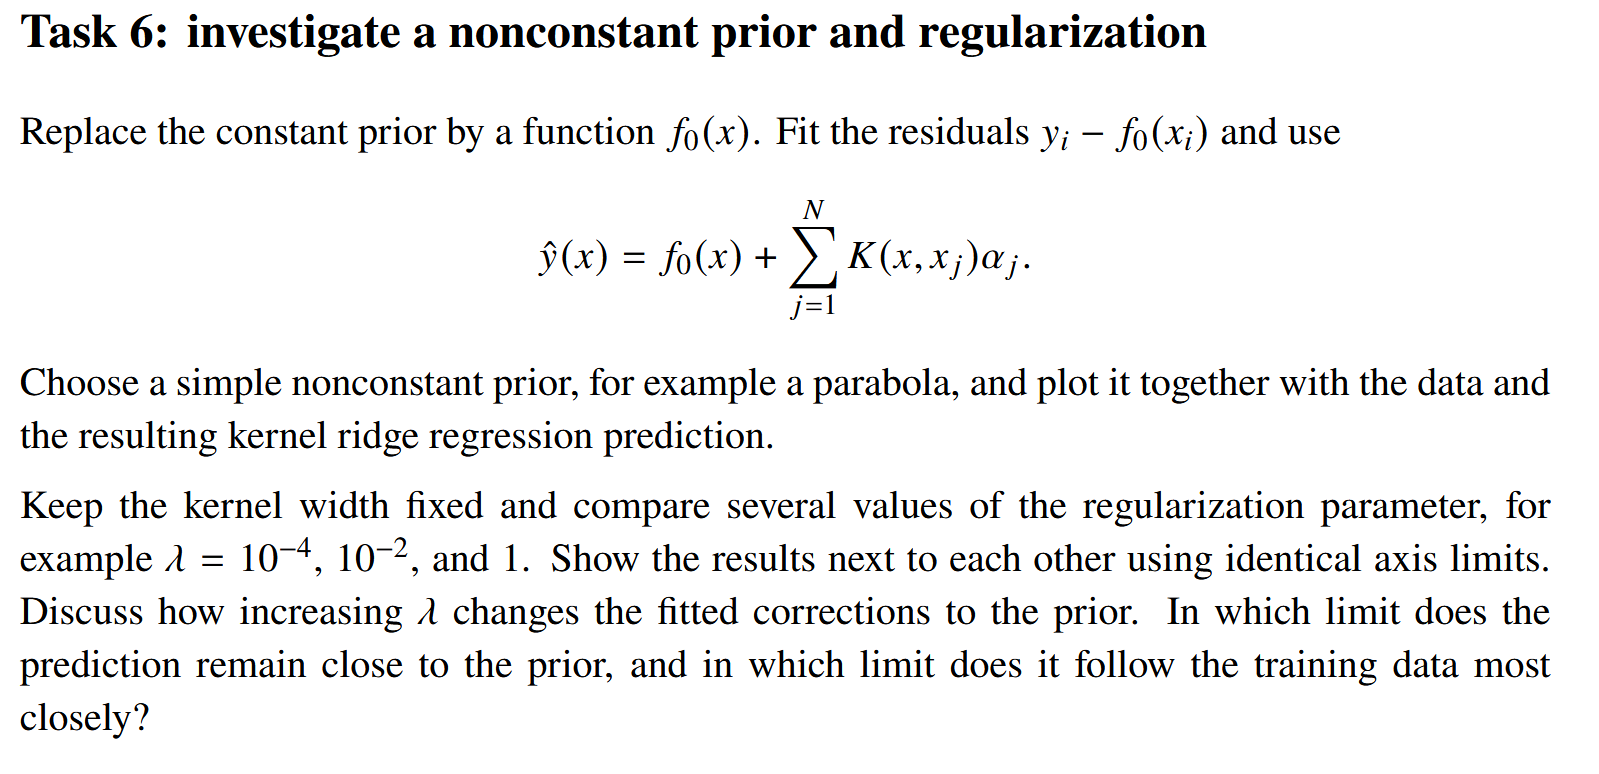

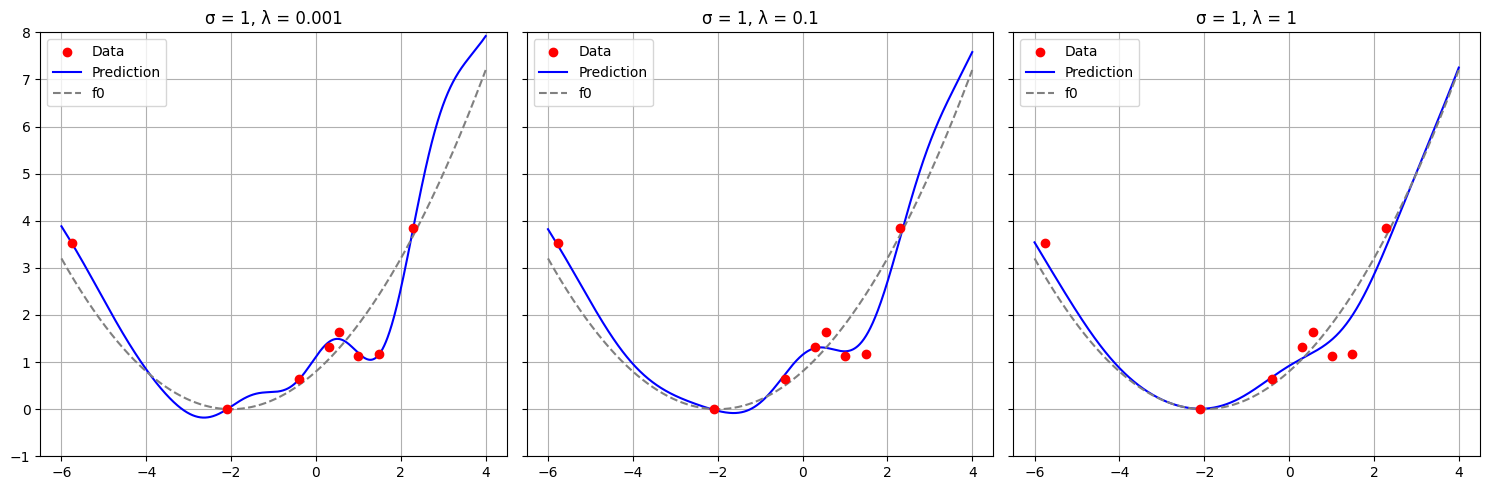

In [57]:
class PriorKernalRidgeRegression(KernalRidgeRegression):
    def __init__(self, *args, f0=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.f0 = f0

    def fit(self, X, y):
        super().fit(X, y)
        
        self.alpha = (np.linalg.inv(self.K_fit + self.l * np.identity(self.N)) 
                      @ (y - self.f0(X)))
        
        return self.alpha
    
    def predict(self, X):
        return super().predict(X) + self.f0(X)

ls = [10e-4, 10e-2, 1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

def func(x):
    return 0.2 * (x + 2)**2 

for ax, l in zip(axes, ls):
    krr = PriorKernalRidgeRegression(1, l, f0=func)
    krr.fit(xs, ys)

    y_lin = krr.predict(x_lin)

    ax.scatter(xs, ys, color='red', zorder=5, label='Data')
    ax.plot(x_lin, y_lin, color='blue', label='Prediction')

    ax.plot(x_lin, func(x_lin), '--', color='gray', label='f0')

    ax.set_ylim(-1, 8)
    ax.set_title(f'σ = {1}, λ = {l}')
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()